In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
print("setup complete")

setup complete


In [3]:
df = pd.read_csv("../data/AirfoilSelfNoise.csv")
print(df.shape)
print(df.columns.tolist())
df.head()

(1503, 6)
['f', 'alpha', 'c', 'U_infinity', 'delta', 'SSPL']


,f,alpha,c,U_infinity,delta,SSPL
0,800,0.0,0.3048,71.3,0.002663,126.201
1,1000,0.0,0.3048,71.3,0.002663,125.201
2,1250,0.0,0.3048,71.3,0.002663,125.951
3,1600,0.0,0.3048,71.3,0.002663,127.591
4,2000,0.0,0.3048,71.3,0.002663,127.461


In [4]:
print(df.describe())
print(df.isna().sum())
print(df.duplicated().sum())

                  f        alpha            c   U_infinity        delta  \
count   1503.000000  1503.000000  1503.000000  1503.000000  1503.000000   
mean    2886.380572     6.782302     0.136548    50.860745     0.011140   
std     3152.573137     5.918128     0.093541    15.572784     0.013150   
min      200.000000     0.000000     0.025400    31.700000     0.000401   
25%      800.000000     2.000000     0.050800    39.600000     0.002535   
50%     1600.000000     5.400000     0.101600    39.600000     0.004957   
75%     4000.000000     9.900000     0.228600    71.300000     0.015576   
max    20000.000000    22.200000     0.304800    71.300000     0.058411   

              SSPL  
count  1503.000000  
mean    124.835943  
std       6.898657  
min     103.380000  
25%     120.191000  
50%     125.721000  
75%     129.995500  
max     140.987000  
f             0
alpha         0
c             0
U_infinity    0
delta         0
SSPL          0
dtype: int64
0


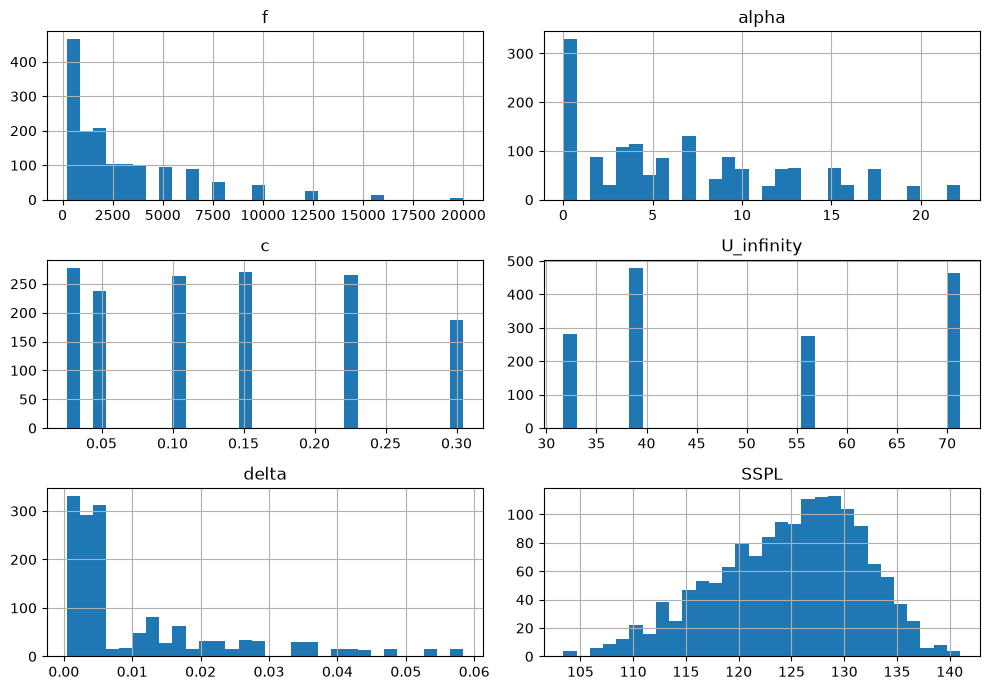

In [5]:
df.hist(figsize=(10, 7), bins=30)
plt.tight_layout()
plt.show()


In [6]:
print(df.skew())

f             2.137084
alpha         0.689164
c             0.457457
U_infinity    0.235852
delta         1.702165
SSPL         -0.418952
dtype: float64


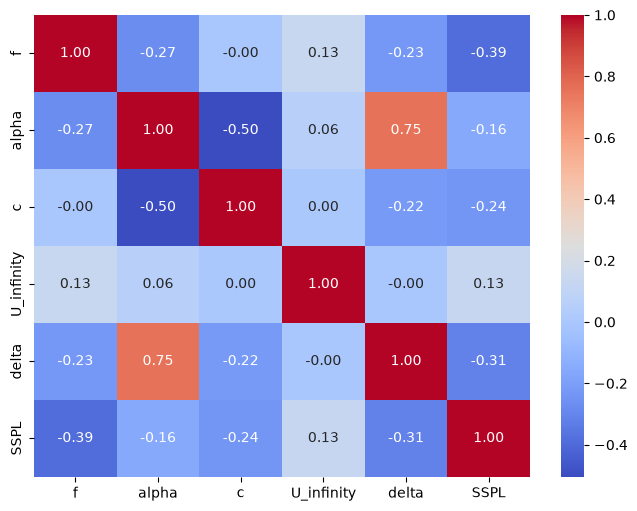

In [7]:
plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.show()

In [8]:
preprocess_v2 = ColumnTransformer([
    ("log1p", Pipeline([("t", FunctionTransformer(np.log1p)), ("s", StandardScaler())]), ["f"]),
    ("log",   Pipeline([("t", FunctionTransformer(np.log)),   ("s", StandardScaler())]), ["delta"]),
    ("sqrt",  Pipeline([("t", FunctionTransformer(np.sqrt)),  ("s", StandardScaler())]), ["alpha"]),
    ("scale", StandardScaler(), ["c", "U_infinity"]),
])

print("delta skew after log:", np.log(df["delta"]).skew().round(2))

for name, reg in [("Linear", LinearRegression()), ("Ridge", Ridge(alpha=1.0)), ("Lasso", Lasso(alpha=0.01))]:
    m = Pipeline([("prep", preprocess_v2), ("m", reg)])
    m.fit(X_train, y_train)
    p = m.predict(X_test)
    print(name, "RMSE:", round(np.sqrt(mean_squared_error(y_test, p)), 3),
          "R2:", round(r2_score(y_test, p), 3))

NameError: name 'ColumnTransformer' is not defined

In [ ]:
models = {
    "Linear":            Pipeline([("prep", preprocess), ("m", LinearRegression())]),
    "Ridge":             Pipeline([("prep", preprocess), ("m", Ridge(alpha=1.0))]),
    "Lasso":             Pipeline([("prep", preprocess), ("m", Lasso(alpha=0.01))]),
    "Random Forest":     RandomForestRegressor(n_estimators=300, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
}

rows = []
for name, m in models.items():
    m.fit(X_train, y_train)
    p = m.predict(X_test)
    rows.append({
        "Model": name,
        "RMSE": np.sqrt(mean_squared_error(y_test, p)),
        "MAE":  mean_absolute_error(y_test, p),
        "R2":   r2_score(y_test, p),
    })

pd.DataFrame(rows).round(3)


,Model,RMSE,MAE,R2
0,Linear,4.945,3.830,0.512
1,Ridge,4.945,3.832,0.512
2,Lasso,4.948,3.835,0.511
3,Random Forest,1.808,1.303,0.935
4,Gradient Boosting,2.861,2.169,0.837


In [ ]:
from sklearn.model_selection import cross_val_score

for name, m in models.items():
    scores = cross_val_score(m, X_train, y_train, cv=5, scoring="r2")
    print(f"{name:18s} R² Avg: {scores.mean():.3f}  (± {scores.std():.3f})")

Linear             R² Avg: 0.446  (± 0.070)
Ridge              R² Avg: 0.446  (± 0.069)
Lasso              R² Avg: 0.446  (± 0.069)
Random Forest      R² Avg: 0.922  (± 0.013)
Gradient Boosting  R² Avg: 0.838  (± 0.020)


In [ ]:
from sklearn.model_selection import GridSearchCV

gb_grid = GridSearchCV(
    GradientBoostingRegressor(random_state=42),
    {
        "n_estimators": [200, 500],
        "learning_rate": [0.05, 0.1],
        "max_depth": [3, 5],
    },
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
)

gb_grid.fit(X_train, y_train)

print("Best configuration:", gb_grid.best_params_)
print("CV RMSE:", round(-gb_grid.best_score_, 3))

Best configuration: {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 500}
CV RMSE: 1.622


In [ ]:
rf_grid = GridSearchCV(
    RandomForestRegressor(random_state=42),
    {"n_estimators": [200, 500],
     "max_depth": [None, 20],
     "min_samples_leaf": [1, 2]},
    cv=5, scoring="neg_root_mean_squared_error", n_jobs=-1
)
rf_grid.fit(X_train, y_train)
print("Best params:", rf_grid.best_params_)
print("CV RMSE:", round(-rf_grid.best_score_, 3))

Best params: {'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 200}
CV RMSE: 1.903


In [ ]:
for name, g in [("Tuned Gradient Boosting", gb_grid), ("Tuned Random Forest", rf_grid)]:
    p = g.predict(X_test)
    print(name, "RMSE:", round(np.sqrt(mean_squared_error(y_test, p)), 3),
          "R2:", round(r2_score(y_test, p), 3))

Tuned Gradient Boosting RMSE: 1.521 R2: 0.954
Tuned Random Forest RMSE: 1.811 R2: 0.935


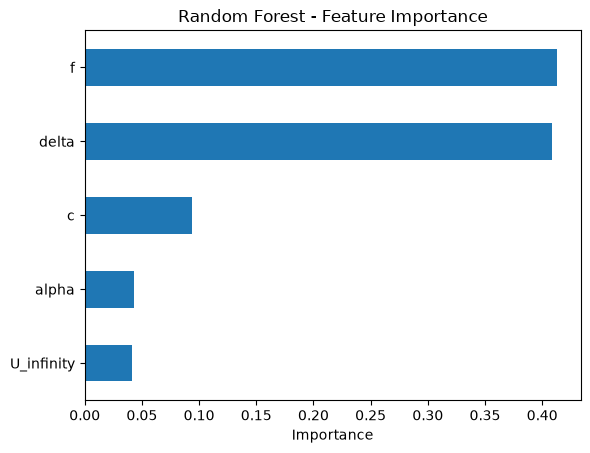

In [ ]:
best_rf = rf_grid.best_estimator_
imp = pd.Series(best_rf.feature_importances_, index=X.columns).sort_values()
imp.plot.barh(title="Random Forest - Feature Importance")
plt.xlabel("Importance")
plt.show()

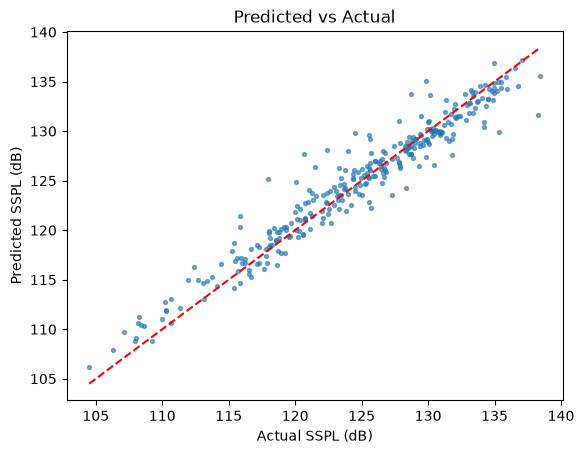

In [ ]:
p = best_rf.predict(X_test)
plt.scatter(y_test, p, s=8, alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
plt.xlabel("Actual SSPL (dB)")
plt.ylabel("Predicted SSPL (dB)")
plt.title("Predicted vs Actual")
plt.show()

In [ ]:
from sklearn.model_selection import cross_val_score

for name, m in models.items():
    scores = cross_val_score(m, X_train, y_train, cv=5, scoring="r2")
    print(f"{name:18s} mean R2: {scores.mean():.3f}  (+/- {scores.std():.3f})")

Linear             mean R2: 0.446  (+/- 0.070)
Ridge              mean R2: 0.446  (+/- 0.069)
Lasso              mean R2: 0.446  (+/- 0.069)
Random Forest      mean R2: 0.922  (+/- 0.013)
Gradient Boosting  mean R2: 0.838  (+/- 0.020)
